In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path

DATA_DIR = Path.cwd() / "data" / "raw"

if not DATA_DIR.exists():
    DATA_DIR = Path.cwd().parent / "data" / "raw"

print(DATA_DIR.resolve())

/workspaces/card-fraud-scoring-platform/data/raw


In [3]:
transactions = pd.read_csv(DATA_DIR / "train_transaction.csv")
identity = pd.read_csv(DATA_DIR / "train_identity.csv")

print("Transactions:", transactions.shape)
print("Identity:", identity.shape)

Transactions: (590540, 394)
Identity: (144233, 41)


In [4]:
transactions.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
identity.head()

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


In [6]:
transactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 394 entries, TransactionID to V339
dtypes: float64(376), int64(4), str(14)
memory usage: 1.7 GB


In [7]:
identity.info()

<class 'pandas.DataFrame'>
RangeIndex: 144233 entries, 0 to 144232
Data columns (total 41 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   TransactionID  144233 non-null  int64  
 1   id_01          144233 non-null  float64
 2   id_02          140872 non-null  float64
 3   id_03          66324 non-null   float64
 4   id_04          66324 non-null   float64
 5   id_05          136865 non-null  float64
 6   id_06          136865 non-null  float64
 7   id_07          5155 non-null    float64
 8   id_08          5155 non-null    float64
 9   id_09          74926 non-null   float64
 10  id_10          74926 non-null   float64
 11  id_11          140978 non-null  float64
 12  id_12          144233 non-null  str    
 13  id_13          127320 non-null  float64
 14  id_14          80044 non-null   float64
 15  id_15          140985 non-null  str    
 16  id_16          129340 non-null  str    
 17  id_17          139369 non-null  float64


In [8]:
transactions.isnull().sum().sort_values(ascending=False).head(15)

dist2    552913
D7       551623
D13      528588
D14      528353
D12      525823
D6       517353
D9       515614
D8       515614
V153     508595
V149     508595
V141     508595
V146     508595
V154     508595
V162     508595
V142     508595
dtype: int64

In [9]:
transactions["isFraud"].value_counts()

isFraud
0    569877
1     20663
Name: count, dtype: int64

In [10]:
transactions["isFraud"].value_counts(normalize=True) * 100

isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64

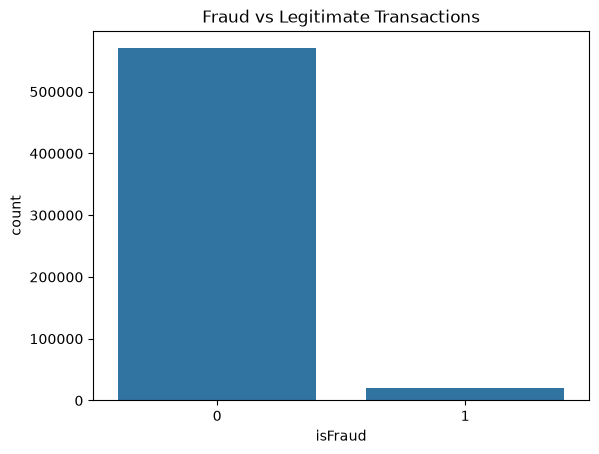

In [11]:
sns.countplot(data=transactions, x="isFraud")
plt.title("Fraud vs Legitimate Transactions")
plt.show()

In [12]:
transactions.groupby("isFraud")["TransactionAmt"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,569877.0,134.511665,239.395078,0.251,43.970,68.5,120.0,31937.391
1,20663.0,149.244779,232.212163,0.292,35.044,75.0,161.0,5191.000


In [13]:
print(transactions["TransactionID"].duplicated().sum())
print(identity["TransactionID"].duplicated().sum())

0
0


In [14]:
transactions["TransactionID"].isin(identity["TransactionID"]).mean() * 100

np.float64(24.42391709283029)

In [15]:
(transactions.isnull().mean() * 100).sort_values(ascending=False).head(15)

dist2    93.628374
D7       93.409930
D13      89.509263
D14      89.469469
D12      89.041047
D6       87.606767
D9       87.312290
D8       87.312290
V153     86.123717
V149     86.123717
V141     86.123717
V146     86.123717
V154     86.123717
V162     86.123717
V142     86.123717
dtype: float64

In [16]:
transactions.groupby("isFraud")["dist2"].apply(
    lambda x: x.isnull().mean() * 100
)

isFraud
0    94.052050
1    81.943571
Name: dist2, dtype: float64

In [17]:
transactions.groupby("isFraud")["D7"].apply(
    lambda x: x.isnull().mean() * 100
)

isFraud
0    94.186991
1    71.978899
Name: D7, dtype: float64

In [18]:
transactions.groupby("isFraud")["TransactionAmt"].mean()

isFraud
0    134.511665
1    149.244779
Name: TransactionAmt, dtype: float64

In [19]:
transactions.groupby("isFraud")["TransactionAmt"].median()

isFraud
0    68.5
1    75.0
Name: TransactionAmt, dtype: float64

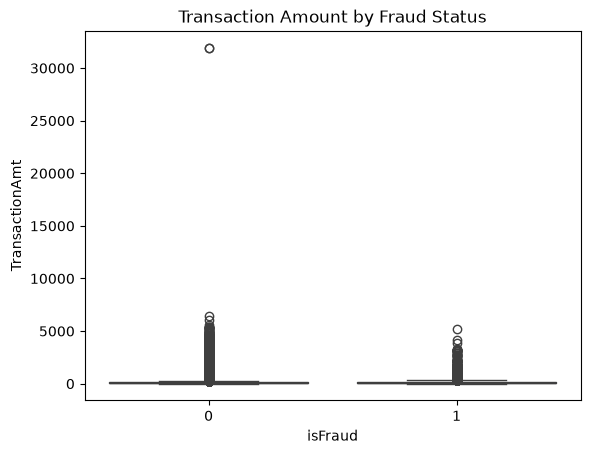

In [20]:
sns.boxplot(data=transactions, x="isFraud", y="TransactionAmt")
plt.title("Transaction Amount by Fraud Status")
plt.show()

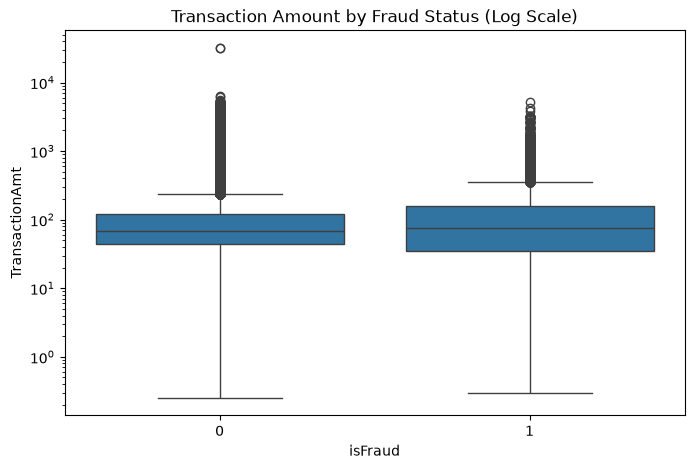

In [21]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=transactions,
    x="isFraud",
    y="TransactionAmt"
)

plt.yscale("log")
plt.title("Transaction Amount by Fraud Status (Log Scale)")
plt.show()

In [22]:
transactions["ProductCD"].value_counts()

ProductCD
W    439670
C     68519
R     37699
H     33024
S     11628
Name: count, dtype: int64

In [23]:
transactions.groupby("ProductCD")["isFraud"].mean() * 100

ProductCD
C    11.687269
H     4.766231
R     3.782594
S     5.899553
W     2.039939
Name: isFraud, dtype: float64

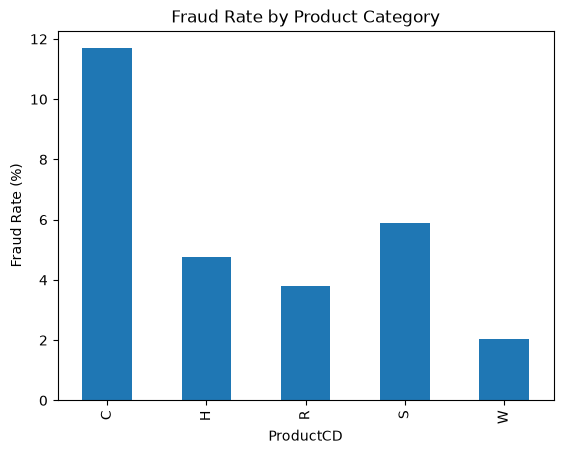

In [24]:
fraud_rate = transactions.groupby("ProductCD")["isFraud"].mean() * 100

fraud_rate.plot(kind="bar", title="Fraud Rate by Product Category")

plt.ylabel("Fraud Rate (%)")
plt.show()

In [25]:
transactions["card4"].value_counts()

card4
visa                384767
mastercard          189217
american express      8328
discover              6651
Name: count, dtype: int64

In [26]:
transactions.groupby("card4")["isFraud"].mean() * 100

card4
american express    2.869837
discover            7.728161
mastercard          3.433095
visa                3.475610
Name: isFraud, dtype: float64

In [27]:
transactions["card6"].value_counts()

card6
debit              439938
credit             148986
debit or credit        30
charge card            15
Name: count, dtype: int64

In [28]:
transactions.groupby("card6")["isFraud"].mean() * 100

card6
charge card        0.000000
credit             6.678480
debit              2.426251
debit or credit    0.000000
Name: isFraud, dtype: float64

In [29]:
transactions.groupby("isFraud")["TransactionDT"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,569877.0,7.360791e+06,4.623930e+06,86400.0,3010651.0,7271678.0,11253338.0,15811131.0
1,20663.0,7.690033e+06,4.416551e+06,89760.0,3965858.0,7575230.0,11217428.0,15810876.0


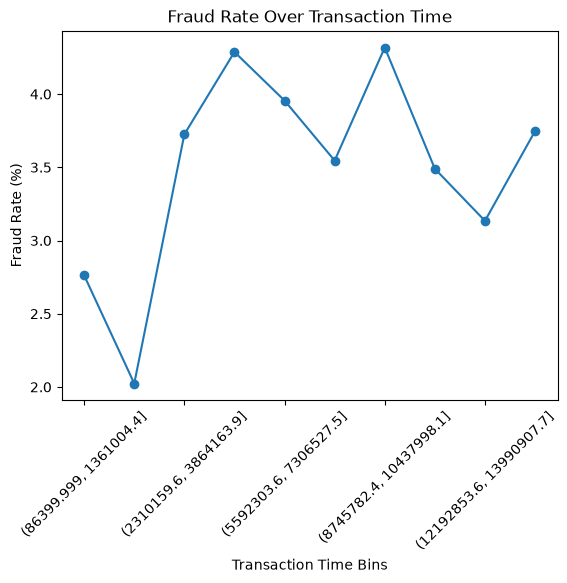

In [30]:
transactions["time_bin"] = pd.qcut(
    transactions["TransactionDT"],
    q=10
)

fraud_time = transactions.groupby(
    "time_bin",
    observed=True
)["isFraud"].mean() * 100

fraud_time.plot(kind="line", marker="o")

plt.title("Fraud Rate Over Transaction Time")
plt.xlabel("Transaction Time Bins")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45)
plt.show()

In [31]:
transactions["TransactionID"].isin(
    identity["TransactionID"]
).mean() * 100

np.float64(24.42391709283029)

In [32]:
merged = transactions.merge(
    identity,
    on="TransactionID",
    how="left"
)

print("Before join:", transactions.shape)
print("After join:", merged.shape)

Before join: (590540, 395)
After join: (590540, 435)


In [33]:
print("Transaction IDs unique:",
      transactions["TransactionID"].is_unique)

print("Identity IDs unique:",
      identity["TransactionID"].is_unique)

Transaction IDs unique: True
Identity IDs unique: True


In [34]:
merged["id_01"].isnull().mean() * 100

np.float64(75.5760829071697)